## IMPORT LIBRARY

In [138]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

LOAD DATASETS

In [139]:
df = pd.read_csv("dataset/olist_orders_dataset.csv")
df2 = pd.read_csv("dataset/olist_order_reviews_dataset.csv")
df3 =pd.read_csv("dataset/olist_order_items_dataset.csv")

In [140]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 21.9 MB
None


In [141]:
print(df2.info())

<class 'pandas.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   review_id                99224 non-null  str  
 1   order_id                 99224 non-null  str  
 2   review_score             99224 non-null  int64
 3   review_comment_title     11568 non-null  str  
 4   review_comment_message   40977 non-null  str  
 5   review_creation_date     99224 non-null  str  
 6   review_answer_timestamp  99224 non-null  str  
dtypes: int64(1), str(6)
memory usage: 17.8 MB
None


In [142]:
df2.sample(5)

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
54509,be54bf9b1295513018f23f90f28cff65,bda372c8f4f99cac883f9f8462f5fdfd,5,NaN,NaN,2018-01-30 00:00:00,2018-01-30 21:22:40
4092,72ffc17df0e7e41a17116aac548eaada,cf3953190a955e0f2e4a8552279713b8,1,NaN,Pedido entregue foi diferente do da imagem do ...,2017-12-06 00:00:00,2017-12-06 21:49:02
69156,546c5fc7a406f1734a427d1c3eee4745,2b3c116f4ae22a4b4a127c73d39f5d6e,5,NaN,Muito bom os produtos,2017-07-01 00:00:00,2017-07-02 18:23:31
68357,fa75ffbb9bfebe89b722cb651b3bb432,ec33c3443b392906a9f78c84c93db4ba,5,NaN,NaN,2018-05-12 00:00:00,2018-05-12 20:06:58
47611,150c9fe913f9d891a3d8d8385618545b,aa26b333bebbd16d5bbc7a070574be08,5,NaN,Adorei... excelente qualidade e custo/ benefício,2017-08-26 00:00:00,2017-09-03 03:39:26


In [143]:
print(df3.info())

<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  str    
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  str    
 3   seller_id            112650 non-null  str    
 4   shipping_limit_date  112650 non-null  str    
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), str(4)
memory usage: 18.4 MB
None


## CEK MISSING VALUE, DUPLICATED, FEATURE SELECTION

### olist_orders_dataset

In [144]:
print("Missing value olist_orders_dataset:")
print(df.isnull().sum())
print("\nJumlah data duplikat:", df.duplicated().sum())

Missing value olist_orders_dataset:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Jumlah data duplikat: 0


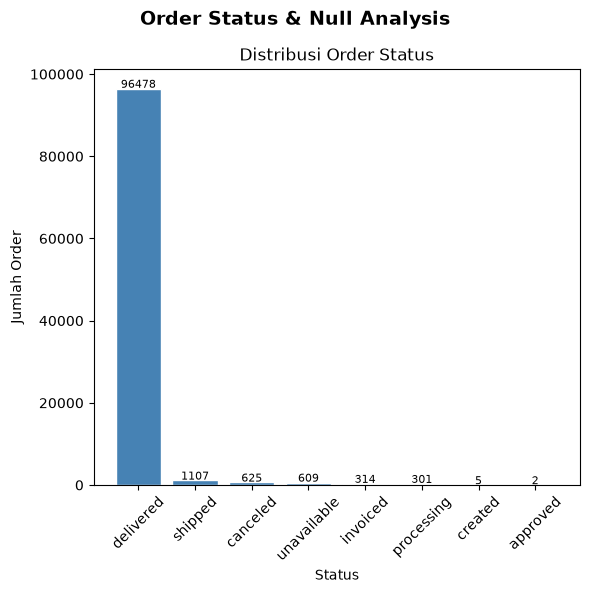

In [145]:
fig, ax = plt.subplots(figsize=(6, 6))
fig.suptitle("Order Status & Null Analysis", fontsize=14, fontweight="bold")

status_counts = df["order_status"].value_counts()

ax.bar(status_counts.index, status_counts.values, color="steelblue", edgecolor="white")
ax.set_title("Distribusi Order Status")
ax.set_xlabel("Status")
ax.set_ylabel("Jumlah Order")
ax.tick_params(axis="x", rotation=45)
for i, v in enumerate(status_counts.values):
    ax.text(i, v + 200, str(v), ha="center", fontsize=8)

plt.tight_layout()
plt.show()

In [146]:
features = ['order_purchase_timestamp', "order_approved_at", "order_delivered_customer_date", "order_estimated_delivery_date"]
df_filtered = df.loc[df["order_status"] == "delivered", features]

In [147]:
print(df_filtered.info())
print("\nCek Null:")
print(df_filtered.isnull().sum())
print("\nCek Duplicated:")
print(df_filtered.duplicated().sum())

<class 'pandas.DataFrame'>
Index: 96478 entries, 0 to 99440
Data columns (total 4 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_purchase_timestamp       96478 non-null  str  
 1   order_approved_at              96464 non-null  str  
 2   order_delivered_customer_date  96470 non-null  str  
 3   order_estimated_delivery_date  96478 non-null  str  
dtypes: str(4)
memory usage: 10.7 MB
None

Cek Null:
order_purchase_timestamp          0
order_approved_at                14
order_delivered_customer_date     8
order_estimated_delivery_date     0
dtype: int64

Cek Duplicated:
0


In [148]:
df_filtered = df_filtered.dropna()
df_filtered.isnull().sum()

order_purchase_timestamp         0
order_approved_at                0
order_delivered_customer_date    0
order_estimated_delivery_date    0
dtype: int64

### olist_order_reviews_dataset

In [149]:
print("Missing value olist_order_reviews_dataset:")
print(df2.isnull().sum())
print("\nJumlah data duplikat:", df2.duplicated().sum())

Missing value olist_order_reviews_dataset:
review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64

Jumlah data duplikat: 0


In [150]:
df2_filtered = df2['review_score']

### olist_order_items_dataset

In [151]:
print("Missing value olist_order_items_dataset:")
print(df3.isnull().sum())
print("\nJumlah data duplikat:", df3.duplicated().sum())

Missing value olist_order_items_dataset:
order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

Jumlah data duplikat: 0


In [152]:
print(df2[["review_score"]].describe())

       review_score
count  99224.000000
mean       4.086421
std        1.347579
min        1.000000
25%        4.000000
50%        5.000000
75%        5.000000
max        5.000000


In [153]:
df3_filtered = df3['shipping_limit_date']

## CEK OUTLIER

In [154]:
print(df3[["price", "freight_value"]].describe())

               price  freight_value
count  112650.000000  112650.000000
mean      120.653739      19.990320
std       183.633928      15.806405
min         0.850000       0.000000
25%        39.900000      13.080000
50%        74.990000      16.260000
75%       134.900000      21.150000
max      6735.000000     409.680000


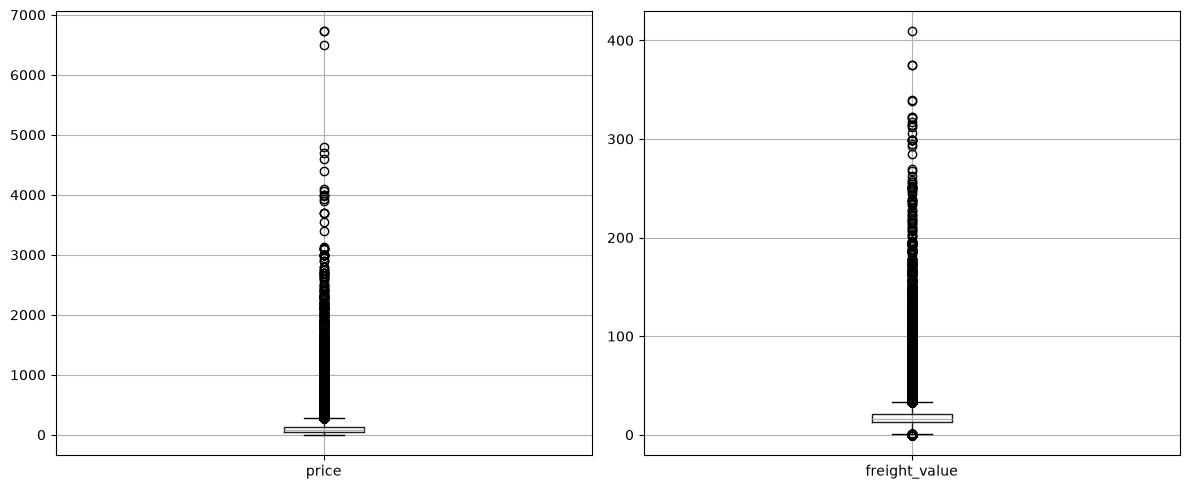

In [155]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
df3.boxplot(column="price", ax=axes[0])
df3.boxplot(column="freight_value", ax=axes[1])
plt.tight_layout()
plt.show()

## FEATURE TERPILIH

In [156]:
print(df_filtered.info())

<class 'pandas.DataFrame'>
Index: 96456 entries, 0 to 99440
Data columns (total 4 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_purchase_timestamp       96456 non-null  str  
 1   order_approved_at              96456 non-null  str  
 2   order_delivered_customer_date  96456 non-null  str  
 3   order_estimated_delivery_date  96456 non-null  str  
dtypes: str(4)
memory usage: 10.7 MB
None


In [157]:
print(df2_filtered.info())

<class 'pandas.Series'>
RangeIndex: 99224 entries, 0 to 99223
Series name: review_score
Non-Null Count  Dtype
--------------  -----
99224 non-null  int64
dtypes: int64(1)
memory usage: 775.3 KB
None


In [158]:
print(df3_filtered.info())

<class 'pandas.Series'>
RangeIndex: 112650 entries, 0 to 112649
Series name: shipping_limit_date
Non-Null Count   Dtype
--------------   -----
112650 non-null  str  
dtypes: str(1)
memory usage: 2.9 MB
None


## FEATURE ENGINEERING

In [ ]:
date_columns = ['order_purchase_timestamp', 'order_approved_at'
                , 'order_delivered_customer_date', 
                'order_estimated_delivery_date']
for col in date_columns:
    df_filtered[col] = pd.to_datetime(df_filtered[col])





# dari checkout sampai ke pelanggan (durasi nyata)
df_filtered['delivery_time'] = (
    df_filtered['order_delivered_customer_date'] - df_filtered['order_purchase_timestamp']
).dt.days

# estimasi dari eccomerce
df_filtered['estimated_delivery_days'] = (
     df_filtered["order_estimated_delivery_date"] - df_filtered["order_purchase_timestamp"]
).dt.days

# delivery di kurang estimasi, kalau minus lebih cepet, kalau plus telat
df_filtered['delivery_delay_days'] = (
    df_filtered['order_delivered_customer_date'] - df_filtered['order_estimated_delivery_date']
).dt.days

# is_late: 1 = terlambat, 0 = tepat waktu / lebih cepat
df_filtered['is_late'] = (df_filtered['delivery_delay_days'] > 0).astype(int)


display(df_filtered.head(100))

# review score mean
review_agg = df2.groupby('order_id')['review_score'].mean()
# print(review_agg)

,order_purchase_timestamp,order_approved_at,order_delivered_customer_date,order_estimated_delivery_date,delivery_time,estimated_delivery_days,delivery_delay_days,is_late
0,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-10 21:25:13,2017-10-18,8,15,-8,0
1,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-08-07 15:27:45,2018-08-13,13,19,-6,0
2,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-17 18:06:29,2018-09-04,9,26,-18,0
3,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-12-02 00:28:42,2017-12-15,13,26,-13,0
4,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-16 18:17:02,2018-02-26,2,12,-10,0
...,...,...,...,...,...,...,...,...
97,2017-11-22 11:32:22,2017-11-22 11:46:50,2017-12-28 19:43:00,2017-12-11,36,18,17,1
98,2017-03-30 07:50:33,2017-03-30 08:05:08,2017-04-10 02:59:52,2017-04-26,10,26,-16,0
99,2018-06-05 09:10:34,2018-06-05 09:32:22,2018-06-18 12:36:54,2018-07-23,13,47,-35,0
100,2018-08-26 11:04:26,2018-08-26 11:15:29,2018-08-28 21:06:31,2018-08-30,2,3,-2,0


## TRAIN TEST SPLIT

In [ ]:
X = 